In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

In [2]:
seed = 42

def random_number():
    global seed
    seed = (16807 * seed) % 2147483647
    return seed / 2147483647

def random_array(n):
    return np.array([random_number() for _ in range(n)])

def random_index(n):
    return int(random_number() * n)

def shuffle_indices(n):
    indices = list(range(n))

    for i in range(n - 1, 0, -1):
        j = random_index(i + 1)
        indices[i], indices[j] = indices[j], indices[i]

    return np.array(indices)

In [3]:
def box_muller(n):
    u1 = np.maximum(random_array(n), 1e-10)
    u2 = random_array(n)

    z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
    z2 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)

    return np.column_stack((z1, z2))

In [4]:
def generate_gaussian(n, mean, sigma_x, sigma_y,
                      covariance_type="spherical", rho=0):

    z = box_muller(n)

    if covariance_type == "spherical":
        x = mean[0] + sigma_x * z[:, 0]
        y = mean[1] + sigma_x * z[:, 1]

    elif covariance_type == "diagonal":
        x = mean[0] + sigma_x * z[:, 0]
        y = mean[1] + sigma_y * z[:, 1]

    else:
        x = mean[0] + sigma_x * z[:, 0]
        y = mean[1] + sigma_y * (
            rho * z[:, 0] + np.sqrt(1 - rho**2) * z[:, 1]
        )

    return np.column_stack((x, y))

In [5]:
n_samples = 1500
K = 3

pi1 = [1/3, 1/3, 1/3]
pi2 = [1/3, 1/3, 1/3]

means_class1 = [
    [3, 2],
    [3, 5],
    [3, 8]
]

means_class2 = [
    [9, 2],
    [9, 5],
    [9, 8]
]

sigma_x = 1.2
sigma_y = 0.8
rho = 0.6

In [6]:
def generate_gmm(n, means, weights, covariance_type,
                 sigma_x, sigma_y, rho):

    component = []

    for i in range(n):
        r = random_number()
        total = 0

        for j in range(len(weights)):
            total += weights[j]

            if r <= total:
                component.append(j)
                break

    component = np.array(component)
    X = np.zeros((n, 2))

    for i in range(len(means)):
        count = np.sum(component == i)

        if count > 0:
            X[component == i] = generate_gaussian(
                count, means[i], sigma_x, sigma_y,
                covariance_type, rho
            )

    return X, component

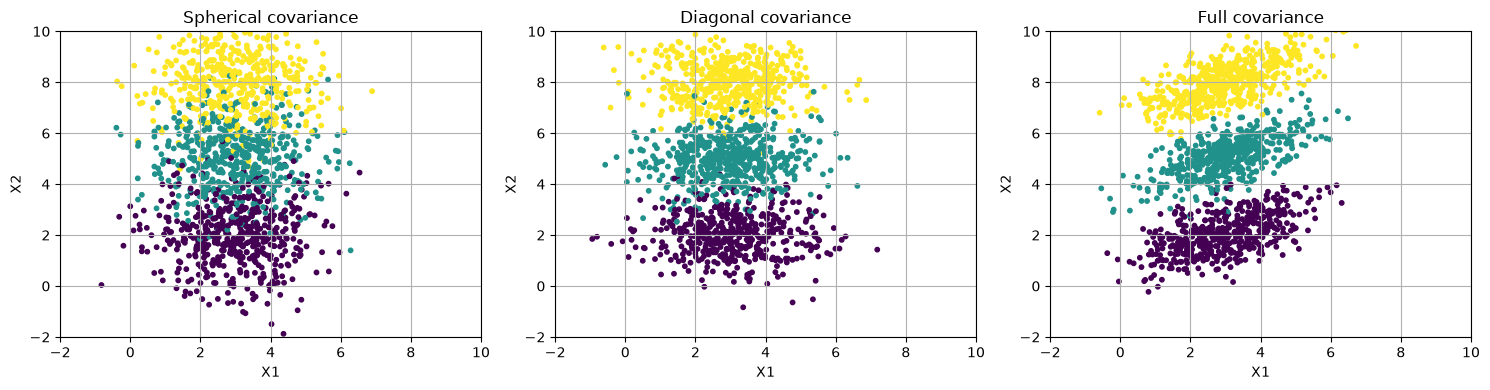

In [7]:
covariance_types = ["spherical", "diagonal", "full"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cov_type in zip(axes, covariance_types):
    X, components = generate_gmm(
        1500, means_class1, pi1, cov_type,
        sigma_x, sigma_y, rho
    )

    ax.scatter(X[:, 0], X[:, 1], c=components, s=10)
    ax.set_title(cov_type.capitalize() + " covariance")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-2, 10)
    ax.set_ylim(-2, 10)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [8]:
X1, component1 = generate_gmm(
    n_samples, means_class1, pi1, "full",
    sigma_x, sigma_y, rho
)

X2, component2 = generate_gmm(
    n_samples, means_class2, pi2, "full",
    sigma_x, sigma_y, rho
)

print("Class 1 data:", X1.shape)
print("Class 2 data:", X2.shape)

Class 1 data: (1500, 2)
Class 2 data: (1500, 2)


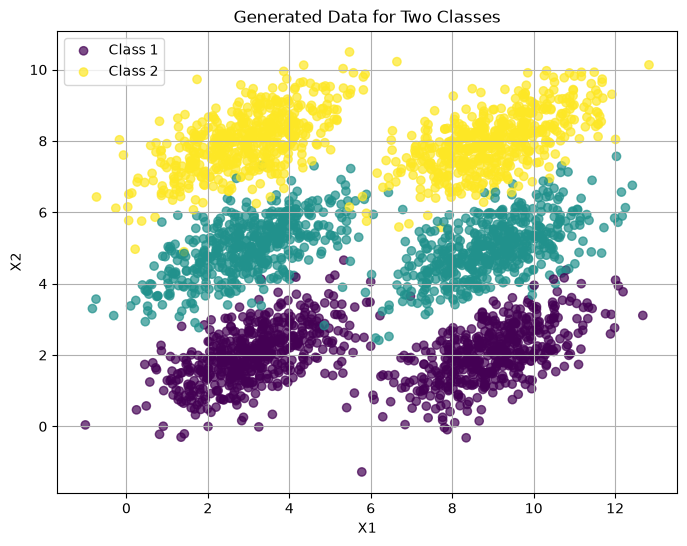

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(X1[:, 0], X1[:, 1], c=component1, label="Class 1", alpha=0.7)
plt.scatter(X2[:, 0], X2[:, 1], c=component2, label="Class 2", alpha=0.7)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Generated Data for Two Classes")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
def train_test_split(X):
    indices = shuffle_indices(len(X))
    split = int(0.8 * len(X))

    train = X[indices[:split]]
    test = X[indices[split:]]

    return train, test

X1_train, X1_test = train_test_split(X1)
X2_train, X2_test = train_test_split(X2)

print("Class 1 training:", len(X1_train))
print("Class 1 testing:", len(X1_test))
print("Class 2 training:", len(X2_train))
print("Class 2 testing:", len(X2_test))

Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300


In [11]:
def kmeans(X, K, max_iterations=100):
    indices = shuffle_indices(len(X))
    centroids = X[indices[:K]].copy()

    for _ in range(max_iterations):
        distances = np.zeros((len(X), K))

        for j in range(K):
            distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()

        for j in range(K):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)

        if np.sum((new_centroids - centroids)**2) < 1e-8:
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.zeros((len(X), K))

    for j in range(K):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    labels = np.argmin(distances, axis=1)

    return centroids, labels

In [12]:
centroids1, labels1 = kmeans(X1_train, K)
centroids2, labels2 = kmeans(X2_train, K)

print("Class 1 centroids:")
print(centroids1)

print("\nClass 2 centroids:")
print(centroids2)

Class 1 centroids:
[[2.99305365 1.99492104]
 [2.98455627 5.09667975]
 [3.05704681 8.09469251]]

Class 2 centroids:
[[8.73455436 1.92465213]
 [9.14531221 7.9490342 ]
 [8.99320369 4.89766787]]


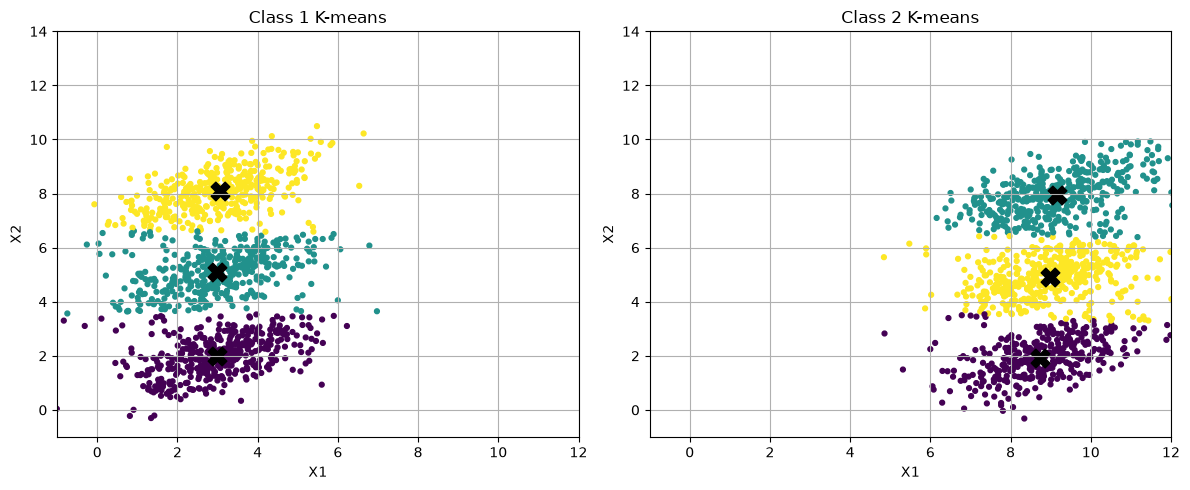

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X1_train[:, 0], X1_train[:, 1], c=labels1, s=12)
axes[0].scatter(centroids1[:, 0], centroids1[:, 1],
                marker="X", s=180, c="black")
axes[0].set_title("Class 1 K-means")

axes[1].scatter(X2_train[:, 0], X2_train[:, 1], c=labels2, s=12)
axes[1].scatter(centroids2[:, 0], centroids2[:, 1],
                marker="X", s=180, c="black")
axes[1].set_title("Class 2 K-means")

for ax in axes:
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-1, 12)
    ax.set_ylim(-1, 14)
    ax.grid(True)

plt.tight_layout()
plt.show()

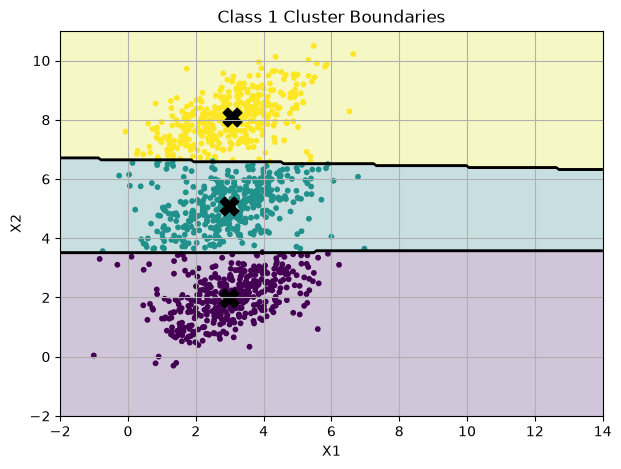

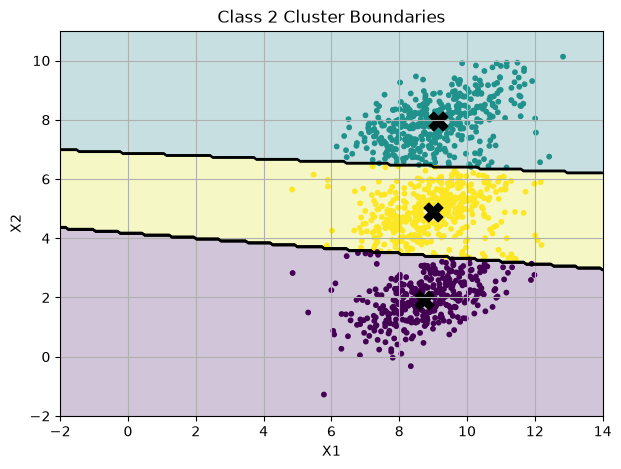

In [14]:

def plot_boundaries(X, centroids, labels, title):
    x_min, x_max = -2, 14
    y_min, y_max = -2, 11

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))
    distances = np.zeros((len(grid), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((grid - centroids[j])**2, axis=1)

    regions = np.argmin(distances, axis=1).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, regions, alpha=0.25)
    plt.contour(xx, yy, regions, colors="black", linewidths=1)

    plt.scatter(X[:, 0], X[:, 1], c=labels, s=10)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker="X", s=180, c="black")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True)
    plt.show()

plot_boundaries(X1_train, centroids1, labels1, "Class 1 Cluster Boundaries")
plot_boundaries(X2_train, centroids2, labels2, "Class 2 Cluster Boundaries")


In [15]:
def calculate_distortion(X, centroids):
    distances = np.zeros((len(X), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    return np.min(distances, axis=1)

def classify(X):
    distortion1 = calculate_distortion(X, centroids1)
    distortion2 = calculate_distortion(X, centroids2)

    predictions = np.where(distortion1 < distortion2, 0, 1)

    return predictions

In [16]:
X_test = np.vstack((X1_test, X2_test))

y_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

predictions = classify(X_test)

accuracy = np.mean(predictions == y_test) * 100

print("Total test samples:", len(X_test))
print("Correct predictions:", np.sum(predictions == y_test))
print("Incorrect predictions:", np.sum(predictions != y_test))
print("Classification accuracy:", round(accuracy, 2), "%")

Total test samples: 600
Correct predictions: 595
Incorrect predictions: 5
Classification accuracy: 99.17 %


In [17]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, predictions):
    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[298   2]
 [  3 297]]


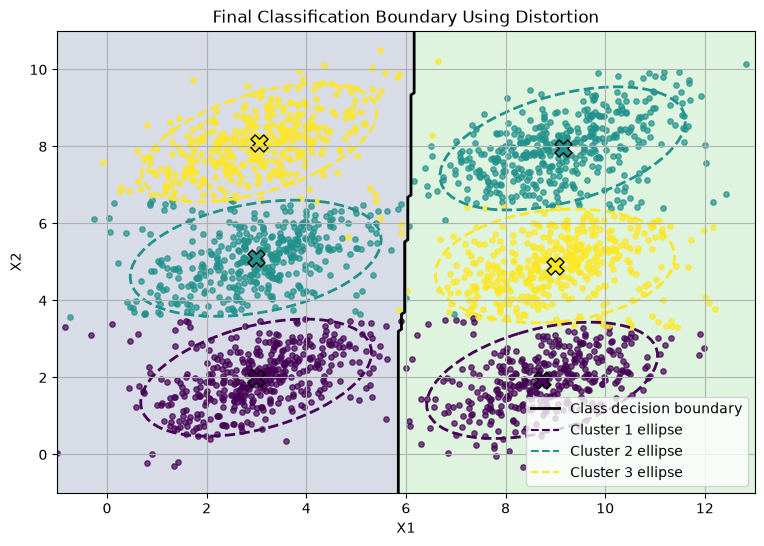

In [18]:

from matplotlib.patches import Ellipse

all_train = np.vstack((X1_train, X2_train))

x_min = all_train[:, 0].min() - 1
x_max = all_train[:, 0].max() + 1
y_min = all_train[:, 1].min() - 1
y_max = all_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.column_stack((xx.ravel(), yy.ravel()))
regions = classify(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, regions,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.2
)

plt.contour(
    xx, yy, regions,
    levels=[0.5],
    colors="black",
    linewidths=2
)

colors = ["#440154", "#21918c", "#fde725"]

for i in range(3):
    plt.scatter(
        X1_train[labels1 == i, 0],
        X1_train[labels1 == i, 1],
        color=colors[i], s=15, alpha=0.7
    )

    plt.scatter(
        X2_train[labels2 == i, 0],
        X2_train[labels2 == i, 1],
        color=colors[i], s=15, alpha=0.7
    )

for X, labels, centroids in [
    (X1_train, labels1, centroids1),
    (X2_train, labels2, centroids2)
]:
    for i in range(3):
        points = X[labels == i]

        center_x = centroids[i, 0]
        center_y = centroids[i, 1]

        cov = np.zeros((2, 2))

        if len(points) > 1:
            centered = points - np.mean(points, axis=0)
            cov = centered.T @ centered / (len(points) - 1)

        values, vectors = np.linalg.eigh(cov)
        order = np.argsort(values)[::-1]
        values = values[order]
        vectors = vectors[:, order]

        angle = np.degrees(np.arctan2(
            vectors[1, 0], vectors[0, 0]
        ))

        width = 4 * np.sqrt(max(values[0], 0))
        height = 4 * np.sqrt(max(values[1], 0))

        plt.gca().add_patch(
            Ellipse(
                (center_x, center_y),
                width=width,
                height=height,
                angle=angle,
                fill=False,
                edgecolor=colors[i],
                linestyle="--",
                linewidth=2
            )
        )

        plt.scatter(
            center_x, center_y,
            marker="X", s=150,
            color=colors[i], edgecolors="black"
        )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Final Classification Boundary Using Distortion")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend(
    handles=[
        plt.Line2D([0], [0], color="black", linewidth=2,
                   label="Class decision boundary"),
        plt.Line2D([0], [0], color=colors[0], linestyle="--",
                   label="Cluster 1 ellipse"),
        plt.Line2D([0], [0], color=colors[1], linestyle="--",
                   label="Cluster 2 ellipse"),
        plt.Line2D([0], [0], color=colors[2], linestyle="--",
                   label="Cluster 3 ellipse")
    ],
    loc="lower right"
)
plt.xlim(-1, 13)
plt.ylim(-1, 11)
plt.grid(True)
plt.show()
